# ReefScan-ID: Stage 1 segmentation

Stage 1 of the cascade: segment a diver photo into coral / substrate / other. Run in Google Colab with a T4 GPU runtime.

### Setup: Colab runtime and Google Drive

In [1]:
import os
import torch
from google.colab import drive


drive.mount("/content/drive")

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
print("GPU: {}".format(gpu_name))

base_dir = "/content/drive/MyDrive/ReefScan-ID"
print("Drive folder found: {}".format(os.path.isdir(base_dir)))

Mounted at /content/drive
GPU: Tesla T4
Drive folder found: True


### Setup: libraries

In [6]:
!pip install -q datasets
import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
print("datasets version: {}".format(datasets.__version__))

datasets version: 4.8.5


## Section 1: Mask ID check

Question: which class ids appear in the Coralscapes masks, and do they match the 39 classes listed on the dataset card?

Checks: count the pixels of every mask value in the train and validation splits, then compare the values found with the ids on the card. The test split is left out here because it is kept for the final evaluation.

### Load the dataset

In [3]:
raw_dir = base_dir + "/RawData"

import time
from datasets import load_dataset


print("Cache folder exists: {}".format(os.path.isdir(raw_dir)))

start = time.time()
ds = load_dataset("EPFL-ECEO/coralscapes", cache_dir=raw_dir)
load_seconds = time.time() - start
print(ds)

cache_bytes = 0
for root, dirs, files in os.walk(raw_dir):
    for name in files:
        cache_bytes += os.path.getsize(os.path.join(root, name))
print("Cache folder size: {:.2f} GB".format(cache_bytes / 1024 ** 3))
print("Loading took {:.1f} seconds".format(load_seconds))

Cache folder exists: True


README.md:   0%|          | 0.00/13.7k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1517
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 166
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 392
    })
})
Cache folder size: 5.45 GB
Loading took 40.2 seconds


### Optional: copy the cache to the Colab disk

Set `use_local_copy = True` to copy the Drive cache to `/content` and load from there. Used to compare the loading time from Drive with the loading time from a local copy.

In [ ]:
import shutil

use_local_copy = False
local_dir = "/content/RawData"

if not use_local_copy:
    print("SKIPPED: local copy not requested")
else:
    start = time.time()
    if not os.path.isdir(local_dir):
        shutil.copytree(raw_dir, local_dir)
    print("Copy took {:.1f} seconds".format(time.time() - start))

    start = time.time()
    ds = load_dataset("EPFL-ECEO/coralscapes", cache_dir=local_dir)
    print("Loading from the local copy took {:.1f} seconds".format(time.time() - start))

SKIPPED: local copy not requested


### Class names from the dataset card

Ids and names copied from the table on the Coralscapes dataset card (read 2026-11-12).

In [8]:
class_names = {
    1: "seagrass",
    2: "trash",
    3: "other coral dead",
    4: "other coral bleached",
    5: "sand",
    6: "other coral alive",
    7: "human",
    8: "transect tools",
    9: "fish",
    10: "algae covered substrate",
    11: "other animal",
    12: "unknown hard substrate",
    13: "background",
    14: "dark",
    15: "transect line",
    16: "massive/meandering bleached",
    17: "massive/meandering alive",
    18: "rubble",
    19: "branching bleached",
    20: "branching dead",
    21: "millepora",
    22: "branching alive",
    23: "massive/meandering dead",
    24: "clam",
    25: "acropora alive",
    26: "sea cucumber",
    27: "turbinaria",
    28: "table acropora alive",
    29: "sponge",
    30: "anemone",
    31: "pocillopora alive",
    32: "table acropora dead",
    33: "meandering bleached",
    34: "stylophora alive",
    35: "sea urchin",
    36: "meandering alive",
    37: "meandering dead",
    38: "crown of thorn",
    39: "dead clam",
}

print("Classes on the card: {}".format(len(class_names)))

Classes on the card: 39


### Count pixels per mask value

In [ ]:
import numpy as np

pixel_counts = {}
for split in ["train", "validation"]:
    counts = np.zeros(256, dtype=np.int64)
    masks = ds[split].select_columns(["label"])
    for row in masks:
        mask = np.array(row["label"])
        counts += np.bincount(mask.ravel(), minlength=256)
    pixel_counts[split] = counts
    print("{}: {} masks counted, {} pixels".format(split, masks.num_rows, counts.sum()))

train: 1517 masks counted, 3181379584 pixels
validation: 166 masks counted, 348127232 pixels


### Mask values found against the card

In [ ]:
import pandas as pd

train_counts = pixel_counts["train"]
val_counts = pixel_counts["validation"]
found = [int(v) for v in np.nonzero(train_counts + val_counts)[0]]

rows = []
for value in found:
    rows.append({
        "id": value,
        "name": class_names.get(value, "NOT ON THE CARD"),
        "train_pct": 100 * train_counts[value] / train_counts.sum(),
        "val_pct": 100 * val_counts[value] / val_counts.sum(),
    })
table = pd.DataFrame(rows)
print(table.to_string(index=False, float_format="{:.3f}".format))

not_on_card = [v for v in found if v not in class_names]
never_seen = [i for i in class_names if i not in found]
print("Mask values found: {}".format(len(found)))
print("Values found that are not on the card: {}".format(not_on_card))
print("Card ids that never appear in train or validation: {}".format(never_seen))

 id                        name  train_pct  val_pct
  0             NOT ON THE CARD     17.048   13.987
  1                    seagrass      0.761    0.000
  2                       trash      0.046    0.006
  3            other coral dead      0.208    2.013
  4        other coral bleached      0.249    0.184
  5                        sand      6.187   11.658
  6           other coral alive      3.781    3.015
  7                       human      1.112    2.039
  8              transect tools      0.071    0.104
  9                        fish      0.469    0.202
 10     algae covered substrate      5.101    1.634
 11                other animal      0.035    0.003
 12      unknown hard substrate     11.909   14.143
 13                  background     21.618   31.457
 14                        dark      5.009    2.717
 15               transect line      0.263    0.255
 16 massive/meandering bleached      0.092    0.670
 17    massive/meandering alive      8.998    3.834
 18         

**Observation**:

## Section 2: Class mapping

Question: how many pixels fall into each stage 1 group (coral / substrate / other) once the 39 Coralscapes classes are mapped to 3?

Checks: build an array that maps every mask value to a group, list the classes in each group, then compute the pixel share of each group on the train and validation splits from the counts of Section 1.

### Build the mapping array

In [9]:
coral_ids = [3, 4, 6, 16, 17, 19, 20, 21, 22, 23, 25, 27, 28, 31, 32, 33, 34, 36, 37]
substrate_ids = [5, 10, 12, 18]
group_names = {0: "coral", 1: "substrate", 2: "other"}
ignore_id = 255

# Values that are not on the card stay at the ignore id
mapping = np.full(256, ignore_id, dtype=np.uint8)
for value in class_names:
    mapping[value] = 2
mapping[coral_ids] = 0
mapping[substrate_ids] = 1

for group_id, group_name in group_names.items():
    names = [class_names[v] for v in class_names if mapping[v] == group_id]
    print("{} ({} ids): {}".format(group_name, len(names), names))
print("Mask value 0 maps to: {}".format(mapping[0]))

coral (19 ids): ['other coral dead', 'other coral bleached', 'other coral alive', 'massive/meandering bleached', 'massive/meandering alive', 'branching bleached', 'branching dead', 'millepora', 'branching alive', 'massive/meandering dead', 'acropora alive', 'turbinaria', 'table acropora alive', 'pocillopora alive', 'table acropora dead', 'meandering bleached', 'stylophora alive', 'meandering alive', 'meandering dead']
substrate (4 ids): ['sand', 'algae covered substrate', 'unknown hard substrate', 'rubble']
other (16 ids): ['seagrass', 'trash', 'human', 'transect tools', 'fish', 'other animal', 'background', 'dark', 'transect line', 'clam', 'sea cucumber', 'sponge', 'anemone', 'sea urchin', 'crown of thorn', 'dead clam']
Mask value 0 maps to: 255


### Pixel share per group

In [ ]:
for split in ["train", "validation"]:
    counts = pixel_counts[split]
    total = counts.sum()
    for group_id, group_name in group_names.items():
        share = 100 * counts[mapping == group_id].sum() / total
        print("{} {}: {:.2f}% of all pixels".format(split, group_name, share))
    ignored = 100 * counts[mapping == ignore_id].sum() / total
    print("{} ignored: {:.2f}% of all pixels".format(split, ignored))

train coral: 25.60% of all pixels
train substrate: 27.53% of all pixels
train other: 29.81% of all pixels
train ignored: 17.05% of all pixels
validation coral: 19.57% of all pixels
validation substrate: 29.36% of all pixels
validation other: 37.08% of all pixels
validation ignored: 13.99% of all pixels


**Observation**:

## Section 3: Crop dataset

Question: does the training data pipeline give random 512 by 512 crops whose images and masks line up, with the masks already mapped to the three groups?

Checks: build a dataset that cuts a random crop from each photo and applies the class mapping to the mask, read one batch from the train and validation loaders, print the shapes, data types and label values, time ten train batches, and draw one crop next to its mask.

### Library versions

In [10]:
import matplotlib

print("torch version: {}".format(torch.__version__))
print("numpy version: {}".format(np.__version__))
print("matplotlib version: {}".format(matplotlib.__version__))

torch version: 2.14.1+cu130
numpy version: 2.4.6
matplotlib version: 3.10.0


### Crop dataset class

In [11]:
import random
from torch.utils.data import Dataset

crop_size = 512


class CropDataset(Dataset):
    def __init__(self, split, crop_size, flip):
        self.split = split
        self.crop_size = crop_size
        self.flip = flip

    def __len__(self):
        return self.split.num_rows

    def __getitem__(self, index):
        row = self.split[index]
        image = np.array(row["image"])
        mask = mapping[np.array(row["label"])]

        # Same random window for the image and the mask
        top = random.randint(0, image.shape[0] - self.crop_size)
        left = random.randint(0, image.shape[1] - self.crop_size)
        image = image[top:top + self.crop_size, left:left + self.crop_size]
        mask = mask[top:top + self.crop_size, left:left + self.crop_size]

        if self.flip and random.random() < 0.5:
            image = image[:, ::-1]
            mask = mask[:, ::-1]

        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(mask.copy()).long()
        return image, mask


print("Crop size: {}".format(crop_size))

Crop size: 512


### Data loaders

In [12]:
from torch.utils.data import DataLoader

batch_size = 8
num_workers = 2

train_data = CropDataset(ds["train"], crop_size, flip=True)
val_data = CropDataset(ds["validation"], crop_size, flip=False)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=num_workers)

print("Train crops per epoch: {}, batches: {}".format(len(train_data), len(train_loader)))
print("Validation crops per epoch: {}, batches: {}".format(len(val_data), len(val_loader)))

Train crops per epoch: 1517, batches: 190
Validation crops per epoch: 166, batches: 21


### One batch check

In [13]:
for name, loader in [("train", train_loader), ("validation", val_loader)]:
    images, masks = next(iter(loader))
    print("{} images: shape {}, dtype {}, min {:.3f}, max {:.3f}".format(
        name, tuple(images.shape), images.dtype, images.min().item(), images.max().item()))
    print("{} masks: shape {}, dtype {}, values {}".format(
        name, tuple(masks.shape), masks.dtype, torch.unique(masks).tolist()))

start = time.time()
steps = 0
for images, masks in train_loader:
    steps += 1
    if steps == 10:
        break
print("Reading {} train batches took {:.1f} seconds".format(steps, time.time() - start))

train images: shape (8, 3, 512, 512), dtype torch.float32, min 0.000, max 1.000
train masks: shape (8, 512, 512), dtype torch.int64, values [0, 1, 2, 255]
validation images: shape (8, 3, 512, 512), dtype torch.float32, min 0.000, max 1.000
validation masks: shape (8, 512, 512), dtype torch.int64, values [0, 1, 2, 255]
Reading 10 train batches took 13.1 seconds


### Crop and mask overlay

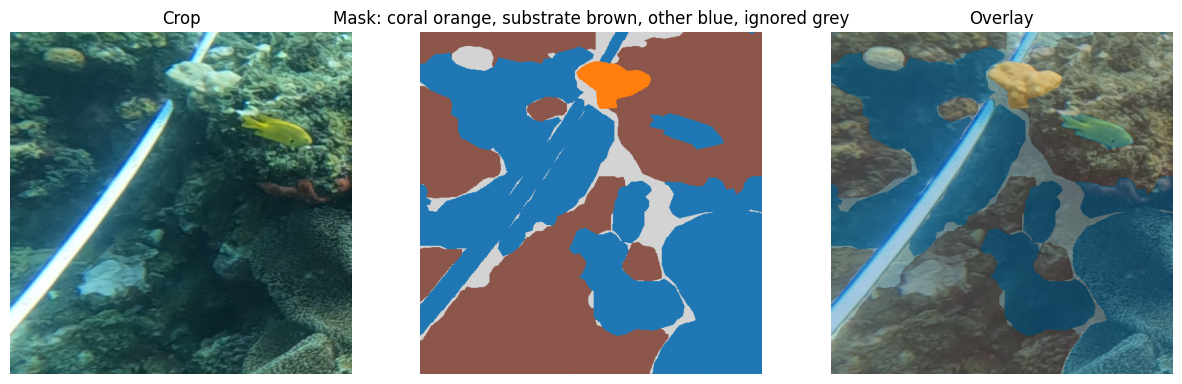

In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

image, mask = train_data[0]
picture = image.permute(1, 2, 0).numpy()
shown = mask.numpy().copy()
shown[shown == ignore_id] = 3
colours = ListedColormap(["tab:orange", "tab:brown", "tab:blue", "lightgrey"])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(picture)
axes[0].set_title("Crop")
axes[1].imshow(shown, cmap=colours, vmin=0, vmax=3)
axes[1].set_title("Mask: coral orange, substrate brown, other blue, ignored grey")
axes[2].imshow(picture)
axes[2].imshow(shown, cmap=colours, vmin=0, vmax=3, alpha=0.4)
axes[2].set_title("Overlay")
for ax in axes:
    ax.axis("off")
plt.show()

**Observation**:

## Section 4: Model

Question: does SegFormer-B0 load with three output classes and run on one batch of crops, and how long does one training step take on the Colab GPU?

Checks: load the model from the pretrained weights and count its parameters, run one forward pass on a train batch and print the output shapes, then time 30 training steps with data loading and the model step measured separately.

### Load SegFormer-B0

In [ ]:
import transformers
from transformers import SegformerForSemanticSegmentation

weights_name = "nvidia/mit-b0"
device = "cuda" if torch.cuda.is_available() else "cpu"

model = SegformerForSemanticSegmentation.from_pretrained(
    weights_name,
    num_labels=len(group_names),
    id2label=group_names,
    label2id={name: group_id for group_id, name in group_names.items()},
    ignore_mismatched_sizes=True,
)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("transformers version: {}".format(transformers.__version__))
print("Weights: {}".format(weights_name))
print("Device: {}".format(device))
print("Parameters: {} total, {} trainable".format(total_params, trainable_params))

### One forward pass

In [ ]:
image_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
image_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

images, masks = next(iter(train_loader))
pixel_values = (images.to(device) - image_mean) / image_std

model.eval()
with torch.no_grad():
    logits = model(pixel_values=pixel_values).logits
upsampled = torch.nn.functional.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

print("Input shape: {}".format(tuple(pixel_values.shape)))
print("Logits shape: {}".format(tuple(logits.shape)))
print("Upsampled logits shape: {}".format(tuple(upsampled.shape)))

### Step timing

In [ ]:
import copy

# Loss and optimiser here are placeholders for timing only
timing_steps = 30
timing_model = copy.deepcopy(model)
timing_model.train()
timing_optimizer = torch.optim.AdamW(timing_model.parameters(), lr=1e-5)

data_seconds = 0.0
step_seconds = 0.0
batches = iter(train_loader)
for step in range(timing_steps):
    start = time.time()
    images, masks = next(batches)
    data_seconds += time.time() - start

    start = time.time()
    pixel_values = (images.to(device) - image_mean) / image_std
    loss = timing_model(pixel_values=pixel_values, labels=masks.to(device)).loss
    timing_optimizer.zero_grad()
    loss.backward()
    timing_optimizer.step()
    if device == "cuda":
        torch.cuda.synchronize()
    step_seconds += time.time() - start

print("Steps timed: {}, batch size: {}".format(timing_steps, batch_size))
print("Data loading: {:.2f} seconds per step".format(data_seconds / timing_steps))
print("Model step: {:.2f} seconds per step".format(step_seconds / timing_steps))
print("Total: {:.2f} seconds per step".format((data_seconds + step_seconds) / timing_steps))

**Observation**: